# 1. Long-horizon assembly from random initial states

**Scientific question.** How often, and how quickly, do the unchanged local social rules generate a persistent connected school from random positions and headings?

**Hypothesis.** Extending the observation window beyond 62.5 s may reveal delayed assembly. A disconnected run at the maximum duration is **right-censored**, not evidence that it can never assemble. The competing possibility is that some configurations remain disconnected throughout the longer window.

**Controlled design.** Thirty explicit seeds (`0…29`), 180 simulated seconds each, 20 fish, a 20 × 20 BL reflecting arena, constant speed 1 BL/s and internal `dt=0.125 s`. Repulsion, orientation and attraction retain their validated reference implementation and radii `0.5 / 3.0 / 5.5 BL`. The baseline uses 360° perception, unlimited social turning and zero angular noise. No light, centroid force, radius tuning, or compact initialization is added.

The reference speed and timestep preserve comparability with Stage 1; this does **not** establish that the same timestep resolves future speeds up to 5 BL/s. Notebook 02 addresses that separate numerical question.

**Literature versus choices.** Local social zones are motivated by [Couzin et al. (2002)](https://doi.org/10.1006/jtbi.2002.3065). Our graph connectivity, persistence windows and 180-s observation limit are diagnostic/experimental choices, not biological constants. No empirical assembly-time distribution is fitted here.

Use the **mesa-env** kernel and **Restart Kernel → Run All**. Every execution below generates the cohort afresh; the later definition and checkpoint notebooks reuse these saved results.

In [1]:
from pathlib import Path
import sys

MODEL_DIR = next(
    folder for parent in (Path.cwd(), *Path.cwd().parents)
    for folder in (parent, parent / "papers")
    if (folder / "shiner_model.py").is_file() and (folder / "handlings").is_dir()
)
if str(MODEL_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_DIR))
HERE = MODEL_DIR / "handlings" / "trial_two"

import json
import time


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

OUTPUT_DIR = MODEL_DIR / "handlings" / "trial_two"
DATA_DIR = OUTPUT_DIR / "data"
FIGURE_DIR = OUTPUT_DIR / "figures"
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)

from handlings.trial_two.study_support import run_streamed

SEEDS = list(range(30))
DURATION_S = 180.0
INTERNAL_DT = 0.125
RECORD_INTERVAL_S = 1.0
CHECKPOINT_DIR = DATA_DIR / "assembly_candidates"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

## Define assembly and censoring before observing the cohort

Two fish are linked when their separation is **at most 5.5 BL**; connected components use transitive graph paths. One component can be an extended chain and need not be a dense biologically realistic school. Mean nearest-neighbour distance alone cannot distinguish one compact school from two compact subgroups.

The main descriptive definition, **B**, is **one component continuously for at least 5 s**. For sensitivity analysis the same observer also tracks **A** (one component for 2.5 s) and **C** (largest component ≥95% of fish for 5 s). With 20 fish C can accept `19+1`; notebook 03 checks whether that changes the conclusion.

- `AssemblyTime` is the first observed connected time of the first episode that subsequently qualifies. It is known retrospectively.
- `AssemblyConfirmedTime` is when the 5-s persistence requirement is met. The cumulative curve uses this confirmation time, avoiding future information at time *t*.
- `Censored=True` means no qualifying episode was confirmed by 180 s. Late connection without enough follow-up is also censored for persistent assembly.
- `PostAssemblyBreakup` records **any** later disconnected internal update after first B confirmation; `BreakupCount` counts entries into such episodes. This conservative check does not require a long breakup.

Connectivity and event timing are checked at **every internal update**. Summary rates use those updates; trace plots sample once per second to avoid large agent tables. Sampled plots can hide brief changes and do not define the events. Persistence refers to the discrete trajectory; changes between internal updates are not observable.

In [2]:
started = time.perf_counter()
summaries, traces = [], []
for seed in SEEDS:
    summary, trace, checkpoint = run_streamed(
        seed=seed, duration=DURATION_S, speed=1.0, dt=INTERNAL_DT,
        record_interval=RECORD_INTERVAL_S,
    )
    summaries.append(summary)
    trace = trace.copy()
    trace["Seed"] = seed
    traces.append(trace)
    candidate_path = CHECKPOINT_DIR / f"seed_{seed}.json"
    if checkpoint is not None:
        candidate_path.write_text(json.dumps(checkpoint, indent=2) + "\n")
    elif candidate_path.exists():
        candidate_path.unlink()  # Do not leave a stale candidate after a rerun.
    if (seed + 1) % 5 == 0:
        print(f"Completed {seed + 1}/{len(SEEDS)} explicit seeds")

summary = pd.DataFrame(summaries).sort_values("Seed").reset_index(drop=True)
traces = pd.concat(traces, ignore_index=True)
summary.to_csv(DATA_DIR / "01_long_horizon_summary.csv", index=False)
traces.to_csv(DATA_DIR / "01_long_horizon_traces.csv", index=False)
elapsed_s = time.perf_counter() - started
assert len(summary) == len(SEEDS) and summary["Seed"].tolist() == SEEDS
assert (summary["AssemblySuccess"] == ~summary["Censored"]).all()
assert (summary.loc[summary["AssemblySuccess"], "AssemblyConfirmedTime"] <= DURATION_S).all()
print(f"Saved {len(summary)} independent runs; {len(traces):,} sampled model rows; runtime {elapsed_s:.1f} s")
display(summary[[
    "Seed", "AssemblySuccess", "AssemblyTime", "AssemblyConfirmedTime", "Censored",
    "ConnectedTimeFraction", "PostAssemblyBreakup", "BreakupCount", "FinalComponentSizes",
]])

Completed 5/30 explicit seeds


Completed 10/30 explicit seeds


Completed 15/30 explicit seeds


Completed 20/30 explicit seeds


Completed 25/30 explicit seeds


Completed 30/30 explicit seeds
Saved 30 independent runs; 5,430 sampled model rows; runtime 28.6 s


,Seed,AssemblySuccess,AssemblyTime,AssemblyConfirmedTime,Censored,ConnectedTimeFraction,PostAssemblyBreakup,BreakupCount,FinalComponentSizes
0,0,True,86.750,91.750,False,0.518750,False,0,20
1,1,True,0.000,5.000,False,1.000000,False,0,20
2,2,True,73.875,78.875,False,0.590278,False,0,20
3,3,True,14.250,19.250,False,0.921528,False,0,20
4,4,True,47.000,52.000,False,0.739583,False,0,20
5,5,True,12.500,17.500,False,0.931250,False,0,20
6,6,True,21.250,26.250,False,0.882639,False,0,20
7,7,True,7.625,12.625,False,0.958333,False,0,20
8,8,True,14.125,19.125,False,0.922222,False,0,20
9,9,True,56.000,61.000,False,0.689583,False,0,20


## Assembly probability and the conditional time distribution

The cumulative curve is `number confirmed by t / 30`, including all censored seeds in the denominator. It is an empirical whole-cohort cumulative fraction, not an ECDF normalized only over successful seeds. All runs share the same administrative censoring horizon, so no unequal follow-up correction is needed.

The histogram deliberately describes only successful runs and uses **episode onset** times. Its denominator and time definition differ from the cumulative confirmation curve. Neither a successful-only median nor the histogram estimates the unconditional waiting-time median when fewer than half of the cohort has assembled.

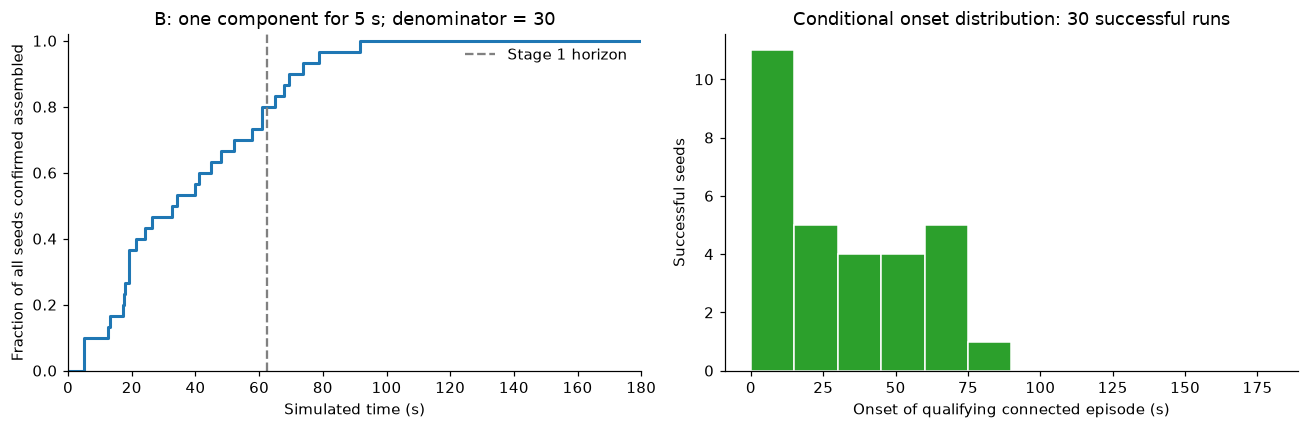

,Quantity,Value
0,Runs,30
1,Confirmed by 62.5 s,24
2,Confirmed by 180 s,30
3,Censored at 180 s,0
4,Assembled runs with any later breakup,0
5,Candidate checkpoints,30


,AssemblyTime,AssemblyConfirmedTime
count,30.000000,30.000000
mean,33.058333,38.058333
std,24.733988,24.733988
min,0.000000,5.000000
25%,13.187500,18.187500
50%,28.500000,33.500000
75%,55.125000,60.125000
max,86.750000,91.750000


In [3]:
assembled = summary[summary["AssemblySuccess"]].copy()
censored = summary[summary["Censored"]].copy()
confirmation_times = np.sort(assembled["AssemblyConfirmedTime"].to_numpy())
success_count = len(assembled)
censored_seeds = censored["Seed"].astype(int).tolist()
breakup_count = int(assembled["PostAssemblyBreakup"].sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.r_[0.0, confirmation_times, DURATION_S]
y = np.r_[0.0, np.arange(1, success_count + 1) / len(SEEDS), success_count / len(SEEDS)]
axes[0].step(x, y, where="post", lw=2)
axes[0].axvline(62.5, color="0.5", ls="--", label="Stage 1 horizon")
axes[0].set(xlabel="Simulated time (s)", ylabel="Fraction of all seeds confirmed assembled",
            xlim=(0, DURATION_S), ylim=(0, 1.02), title="B: one component for 5 s; denominator = 30")
axes[0].legend(frameon=False)
axes[1].hist(assembled["AssemblyTime"], bins=np.linspace(0, DURATION_S, 13),
             edgecolor="white", color="tab:green")
axes[1].set(xlabel="Onset of qualifying connected episode (s)", ylabel="Successful seeds",
            title=f"Conditional onset distribution: {success_count} successful runs")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "01_assembly_cumulative_and_histogram.png", bbox_inches="tight")
plt.show()

by_old_horizon = int((summary["AssemblyConfirmedTime"] <= 62.5).sum())
display(pd.DataFrame({
    "Quantity": ["Runs", "Confirmed by 62.5 s", "Confirmed by 180 s", "Censored at 180 s",
                 "Assembled runs with any later breakup", "Candidate checkpoints"],
    "Value": [len(summary), by_old_horizon, success_count, len(censored), breakup_count,
              len(list(CHECKPOINT_DIR.glob("seed_*.json")))],
}))
if success_count:
    display(assembled[["AssemblyTime", "AssemblyConfirmedTime"]].describe(percentiles=[.25, .5, .75]))

## Fast, slow, and censored examples

Select the fastest and slowest successful onsets and, if present, the first censored seed. This is an explicit descriptive selection, not a representative random subsample. The first two panels expose connectivity directly; the spacing panel shows why MeanNND and distance to the centroid add different information.

The dashed line marks B **confirmation**, rather than onset. One-second plots support interpretation; the summary's breakup fields retain every-update temporal resolution.

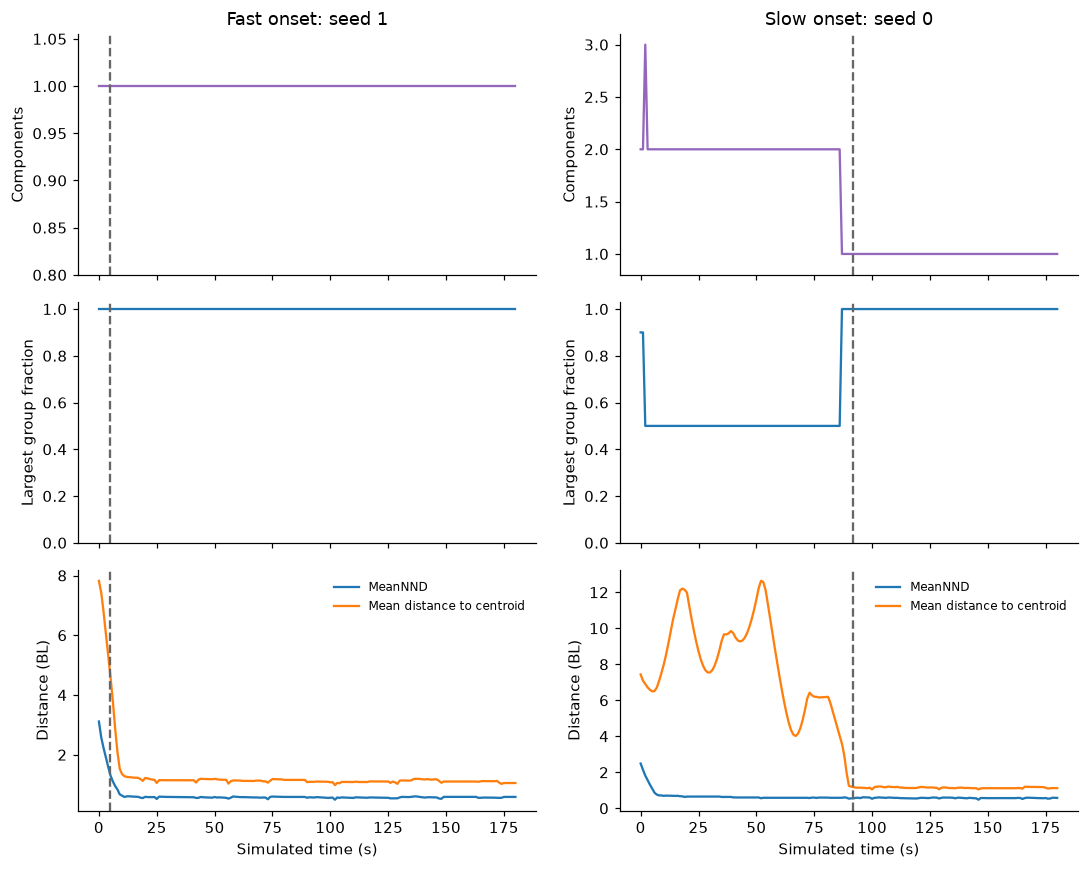

,Seed,FirstConnectionTime,AssemblyTime,AssemblyConfirmedTime,Censored,PostAssemblyBreakup,FinalComponentSizes
0,0,86.750,86.750,91.750,False,False,20
1,1,0.000,0.000,5.000,False,False,20
2,2,73.875,73.875,78.875,False,False,20


,Seed,FirstConnectionTime,FinalComponentSizes,ConnectedTimeFraction


In [4]:
examples = []
if success_count:
    fast = int(assembled.sort_values(["AssemblyTime", "Seed"]).iloc[0]["Seed"])
    slow = int(assembled.sort_values(["AssemblyTime", "Seed"]).iloc[-1]["Seed"])
    examples.extend([(fast, "Fast onset"), (slow, "Slow onset")])
if len(censored):
    examples.append((int(censored.iloc[0]["Seed"]), "Censored"))
examples = list(dict((seed, label) for seed, label in examples).items())
fig, axes = plt.subplots(3, len(examples), figsize=(5 * len(examples), 8), squeeze=False, sharex="col")
for col, (seed, label) in enumerate(examples):
    frame = traces[traces["Seed"] == seed]
    row = summary.set_index("Seed").loc[seed]
    axes[0, col].plot(frame["Time"], frame["NumberOfGroups"], color="tab:purple")
    axes[0, col].set(title=f"{label}: seed {seed}", ylabel="Components", ylim=(.8, None))
    axes[1, col].plot(frame["Time"], frame["LargestGroupFraction"], color="tab:blue")
    axes[1, col].set(ylabel="Largest group fraction", ylim=(0, 1.03))
    axes[2, col].plot(frame["Time"], frame["MeanNND"], label="MeanNND")
    axes[2, col].plot(frame["Time"], frame["MeanDistanceToCentroid"], label="Mean distance to centroid")
    axes[2, col].set(xlabel="Simulated time (s)", ylabel="Distance (BL)")
    axes[2, col].legend(frameon=False, fontsize=8)
    if row["AssemblySuccess"]:
        for ax in axes[:, col]:
            ax.axvline(row["AssemblyConfirmedTime"], color="0.4", ls="--")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "01_fast_slow_censored_examples.png", bbox_inches="tight")
plt.show()

display(summary[summary["Seed"].isin([0, 1, 2])][[
    "Seed", "FirstConnectionTime", "AssemblyTime", "AssemblyConfirmedTime", "Censored",
    "PostAssemblyBreakup", "FinalComponentSizes",
]])
display(censored[["Seed", "FirstConnectionTime", "FinalComponentSizes", "ConnectedTimeFraction"]])

## What these observations establish, and their limits

The result below is generated from the executed cohort. A post-assembly breakup is a loss of whole-group graph connectivity; it does not identify which subgroup split or track subgroup lineage. Follow-up after confirmation differs by seed, so the proportion with any breakup is **not** a time-normalized breakup hazard.

Candidate checkpoints are saved at the **first B confirmation** for every successful seed, without selecting visually attractive states. They contain full state and random-generator information for notebook 04's reconstruction and continuation checks. They are candidates until those checks pass.

In [5]:
if success_count:
    onset = assembled["AssemblyTime"]
    onset_text = (f"Successful onsets range from **{onset.min():.3f} to {onset.max():.3f} s**; "
                  f"their conditional median is **{onset.median():.3f} s** "
                  f"(IQR {onset.quantile(.25):.3f}–{onset.quantile(.75):.3f} s).")
    breakup_text = f"**{breakup_count}/{success_count}** confirmed runs have a later disconnected update."
else:
    onset_text = "No run has a confirmed qualifying episode; conditional onset statistics are undefined."
    breakup_text = "Post-assembly breakup frequency is undefined because no run assembled."
gained = success_count - by_old_horizon
display(Markdown(
    f"**Executed finding.** **{success_count}/{len(summary)} ({success_count / len(summary):.1%})** "
    f"meet B by {DURATION_S:g} s; **{len(censored)}** are right-censored "
    f"(seeds `{censored_seeds}`). {onset_text}\n\n"
    f"Extending the same persistent-assembly assessment from 62.5 to 180 s adds **{gained}** confirmed runs. "
    f"{breakup_text} This tests delayed assembly, rather than assuming disconnected states are permanent.\n\n"
    "**Limits.** These are 30 explicit seeds at one reference speed, finite follow-up, a geometric graph "
    "definition, and discretely observed persistence. Longer waiting times remain unknown for censored seeds. "
    "Connectivity alone does not validate fish biology. Notebook 02 must assess high-speed temporal resolution; "
    "notebook 03 compares diagnostic conventions, and notebook 04 verifies the saved states."
))

**Executed finding.** **30/30 (100.0%)** meet B by 180 s; **0** are right-censored (seeds `[]`). Successful onsets range from **0.000 to 86.750 s**; their conditional median is **28.500 s** (IQR 13.188–55.125 s).

Extending the same persistent-assembly assessment from 62.5 to 180 s adds **6** confirmed runs. **0/30** confirmed runs have a later disconnected update. This tests delayed assembly, rather than assuming disconnected states are permanent.

**Limits.** These are 30 explicit seeds at one reference speed, finite follow-up, a geometric graph definition, and discretely observed persistence. Longer waiting times remain unknown for censored seeds. Connectivity alone does not validate fish biology. Notebook 02 must assess high-speed temporal resolution; notebook 03 compares diagnostic conventions, and notebook 04 verifies the saved states.

## Interpretation of the executed reference cohort

The longer horizon resolves both previously highlighted cases: **seed 0** first connects at **86.750 s** and confirms at **91.750 s**; **seed 2** first connects at **73.875 s** and confirms at **78.875 s**. Their earlier 62.5-s non-assembly was an observation-window result in these trajectories, not an inability to assemble.

Three seeds (**1, 22, 26**) are already connected at `t=0`; their onset time is zero and confirmation occurs at 5 s. Thus the 30/30 criterion-success result includes **27/27 initially disconnected runs that subsequently assemble**, plus three initially connected runs. The fastest-onset illustration is an initially connected example, so it should not be interpreted as newly forming a school at time zero.

There is **no censored seed at 180 s**, so no censored example is fabricated for the figure. Six runs are still unconfirmed under B at 62.5 s. Post-confirmation follow-up ranges from **88.25 to 175 s** across seeds; zero observed breakups is evidence of stability over those intervals, not proof of permanent stability. The result concerns the reference model at speed 1 BL/s only.
